# 01 — Decomposing information by injury type

**Question.** Which feature families carry ranking and warning information, and does Statcast add value beyond workload/history?

**Cohort.** The existing seven-category, 30-day comparison cohorts are reused. Each category compares eligible impending injuries against the same observed IL-free pool; competing injuries are excluded. Training ends in 2021, validation covers 2022–2023, and the already examined 2024–2025 test period remains exploratory. No new claim of untouched confirmation is made. Model variants use identical rows within each comparison.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_signals.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.signals_common import CFG,OUT,CACHE,inputs,read_table
from src.injury_analysis.common import conclusion
from src.injury_analysis import signal_plots as plots
pd.set_option('display.max_columns',16)


## Design and safeguards
Compare every single family, meaningful combinations, workload + history (WH), and all 62 historical predictors. Fit the same logistic regression with C=1 for every specification; no hyperparameter search. Training-only median imputation/scaling leaves stored NULLs intact. Covariates contain no future injury/activation/surgery information. The prediction time remains after a completed outing.

Paired pitcher bootstrap draws compare AP on the **same rows** for all variants. Intervals condition on fitted models; they do not refit the training procedure or correct for all exploratory comparisons. Event recall requires warnings 7–30 days before injury and retains events without observed warning outings in its denominator. Random-alert expectations account for multiple opportunities per event.

In [2]:
from src.injury_analysis.family_decomposition import run_decomposition,run_modern
a,events,spec,matches=inputs()
metrics=run_decomposition(a,events,spec)
display(read_table('family_definitions')[['variant','features']])
display(read_table('family_cohort_counts'))
print(f'Existing source: {len(a):,} pitcher appearances; {events.target_eligible.sum():,} eligible injury targets; {len(matches):,} matched trajectory pairs.')

Family decomposition: Elbow / UCL; events={'train': 223, 'validation': 89, 'test': 110}


Family decomposition: Shoulder; events={'train': 350, 'validation': 115, 'test': 125}


Family decomposition: Forearm; events={'train': 109, 'validation': 41, 'test': 38}


Family decomposition: Other arm; events={'train': 107, 'validation': 33, 'test': 38}


Family decomposition: Trunk / neck; events={'train': 272, 'validation': 103, 'test': 65}


Family decomposition: Lower body; events={'train': 361, 'validation': 130, 'test': 104}


Family decomposition: Hand / wrist; events={'train': 107, 'validation': 32, 'test': 29}


,variant,features
0,command,8
1,extension,4
2,pitch_mix,6
3,pitcher_history,7
4,release_mechanics,8
5,spin_movement,7
6,velocity,7
7,workload,15
8,Workload + history,22
9,Velocity + mechanics,19


,category,partition,rows,events,positives,predictors,run
0,Elbow / UCL,train,81145,223,1441,62,True
1,Elbow / UCL,validation,26796,89,600,62,True
2,Elbow / UCL,test,27665,110,708,62,True
3,Shoulder,train,81978,350,2274,62,True
4,Shoulder,validation,26932,115,736,62,True
5,Shoulder,test,27806,125,849,62,True
6,Forearm,train,80362,109,658,62,True
7,Forearm,validation,26478,41,282,62,True
8,Forearm,test,27236,38,279,62,True
9,Other arm,train,80373,107,669,62,True


Existing source: 233,433 pitcher appearances; 3,552 eligible injury targets; 1,225 matched trajectory pairs.


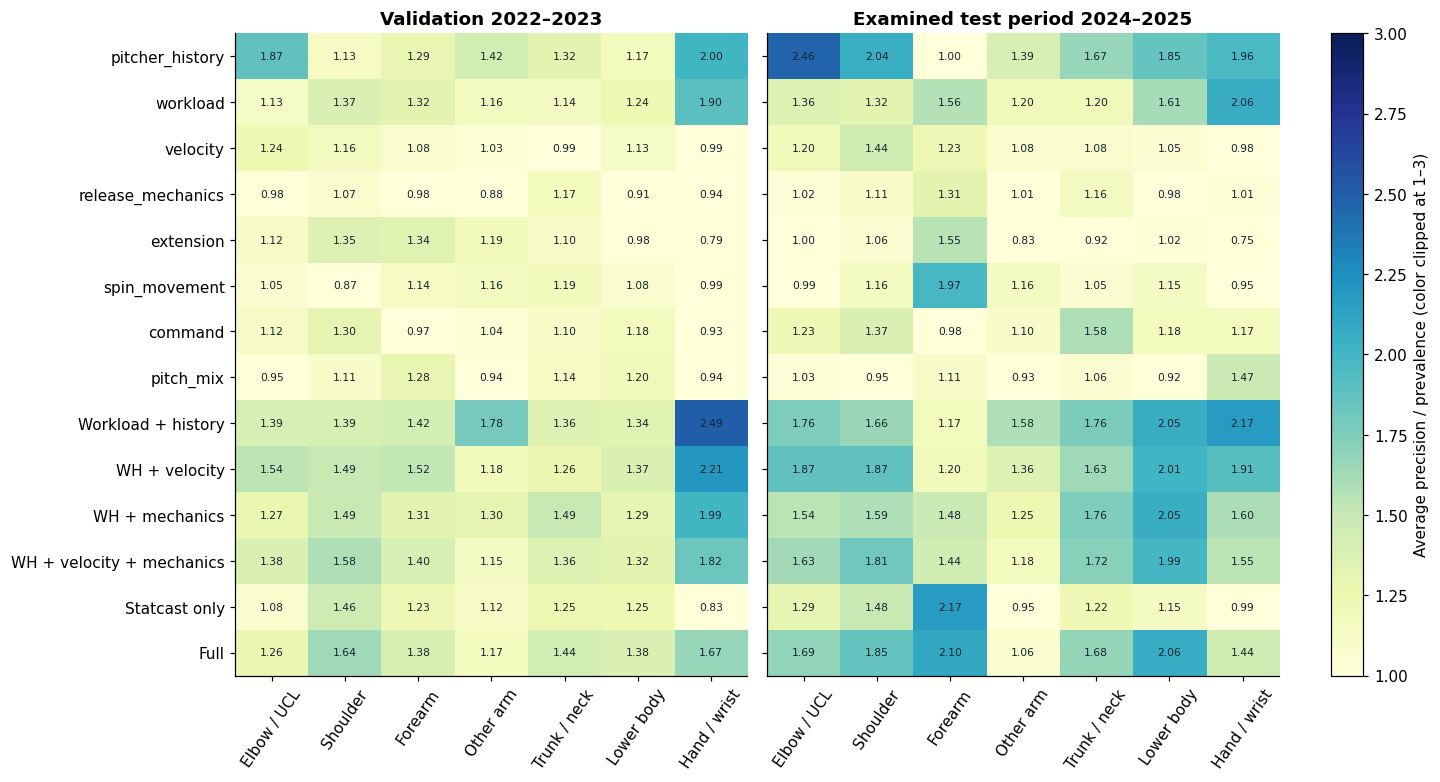

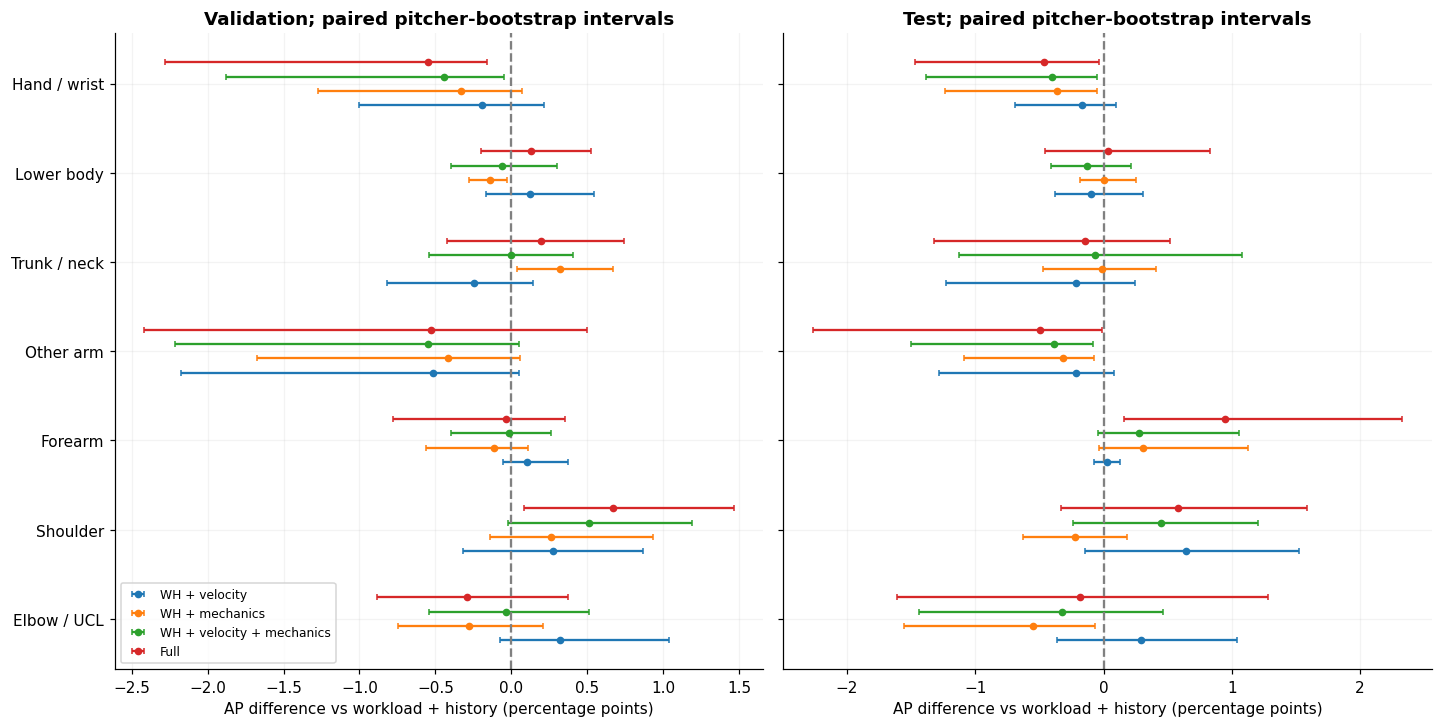

,category,partition,average_precision,pr_lift,ap_delta,delta_low,delta_high
17,Elbow / UCL,validation,0.028254,1.261832,-0.002944,-0.008819,0.003749
35,Elbow / UCL,test,0.043153,1.686216,-0.001814,-0.016062,0.012838
53,Shoulder,validation,0.044729,1.636730,0.006693,0.000816,0.014666
71,Shoulder,test,0.056502,1.850517,0.005829,-0.003308,0.015867
89,Forearm,validation,0.014749,1.384853,-0.000353,-0.007812,0.003507
107,Forearm,test,0.021464,2.095354,0.009443,0.001584,0.023286
125,Other arm,validation,0.010068,1.171981,-0.005255,-0.024177,0.005017
143,Other arm,test,0.010117,1.063066,-0.004960,-0.022673,-0.000138
161,Trunk / neck,validation,0.036355,1.436897,0.001951,-0.004215,0.007456
179,Trunk / neck,test,0.027586,1.676432,-0.001455,-0.013201,0.005185


In [3]:
plots.family_overview();plt.show()
plots.incremental_effects();plt.show()
display(metrics[metrics.variant.eq('Full')][['category','partition','average_precision','pr_lift','ap_delta','delta_low','delta_high']])

## Practical alert performance
Average precision and event detection answer different questions. An above-prevalence row-ranking score need not beat random event detection by much. The following compares the simple baseline, a velocity/mechanics extension and the full model at identical budgets. All-event and observable-event denominators, precision, recall, lead times and non-actionable burden are saved. Seven-day eligibility means an alert one day before placement is too late for this practical objective.

The event-recall difference intervals resample a pitcher's events conditional on fixed observed top-5% selections. Uniform-random values are exact expectations, not a simulated deployed policy. Validation-fixed thresholds are saved separately because test alert rates can drift.

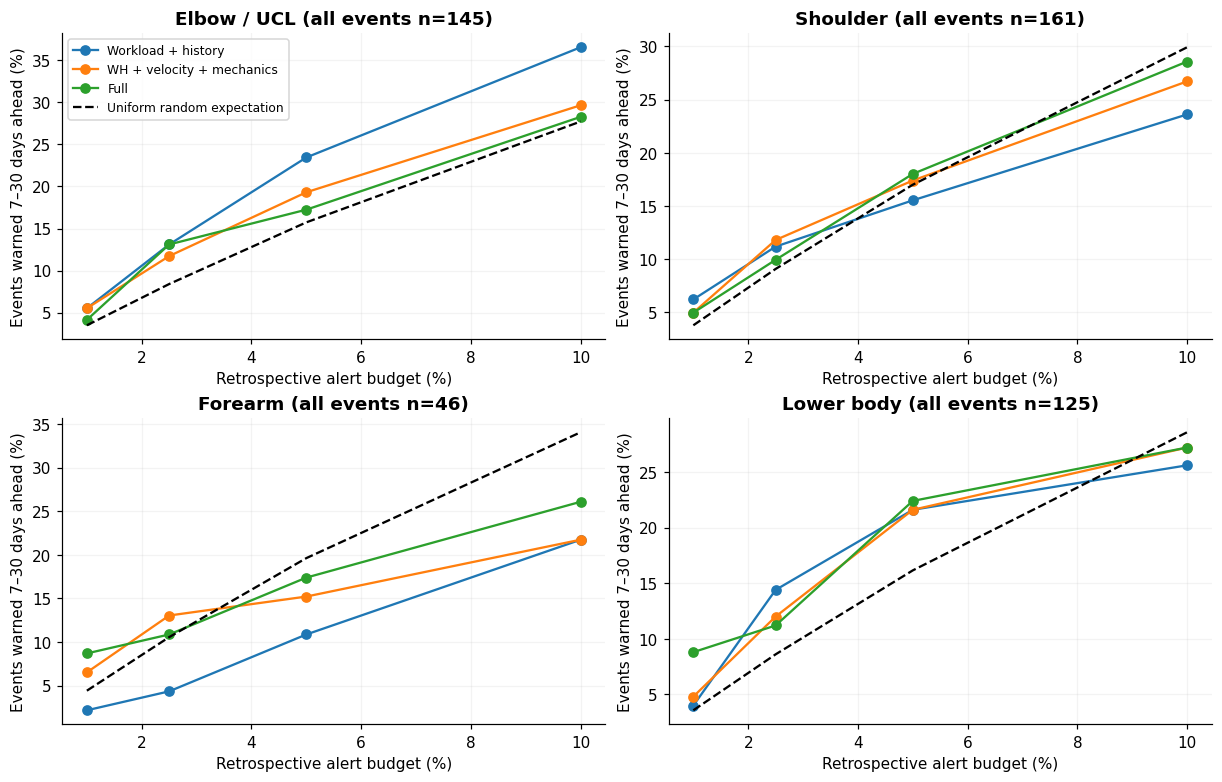

,category,variant,qualifying_events,observable_events,injury_event_recall,random_expected_event_recall,precision,median_warning_lead_days,non_actionable_alerts_per_pitcher_season
106,Elbow / UCL,Workload + history,145,104,0.234483,0.157328,0.067968,18.0,1.101086
142,Elbow / UCL,Full,145,104,0.172414,0.157328,0.054230,17.0,1.112782
250,Shoulder,Workload + history,161,117,0.155280,0.169961,0.069784,22.0,1.111577
286,Shoulder,Full,161,117,0.180124,0.169961,0.078417,18.0,1.116611
394,Forearm,Workload + history,46,36,0.108696,0.196262,0.006613,26.0,1.150382
430,Forearm,Full,46,36,0.173913,0.196262,0.034533,26.5,1.124044
538,Other arm,Workload + history,45,35,0.177778,0.184383,0.019853,23.5,1.134404
574,Other arm,Full,45,35,0.088889,0.184383,0.008824,27.5,1.142857
682,Trunk / neck,Workload + history,85,60,0.188235,0.174037,0.053285,26.5,1.107173
718,Trunk / neck,Full,85,60,0.188235,0.174037,0.043796,22.0,1.118143


,analysis,category,partition,variant,reference,mean,low,high,events,pitchers
70,long_history,Elbow / UCL,test,Full,Workload + history,-0.062069,-0.136107,0.007131,145,129
71,long_history,Elbow / UCL,test,Full,Uniform random expectation,0.015086,-0.041803,0.076341,145,129
142,long_history,Shoulder,test,Full,Workload + history,0.024845,-0.027250,0.075498,161,143
143,long_history,Shoulder,test,Full,Uniform random expectation,0.010163,-0.043958,0.074373,161,143
214,long_history,Forearm,test,Full,Workload + history,0.065217,-0.055830,0.175942,46,43
215,long_history,Forearm,test,Full,Uniform random expectation,-0.022349,-0.112460,0.073002,46,43
286,long_history,Other arm,test,Full,Workload + history,-0.088889,-0.189594,0.000000,45,42
287,long_history,Other arm,test,Full,Uniform random expectation,-0.095494,-0.175004,0.006557,45,42
358,long_history,Trunk / neck,test,Full,Workload + history,0.000000,-0.065949,0.068593,85,75
359,long_history,Trunk / neck,test,Full,Uniform random expectation,0.014198,-0.075127,0.106674,85,75


In [4]:
plots.alert_comparison();plt.show()
budgets=read_table('family_alert_budgets')
display(budgets.query("partition=='test' and alert_rate==0.05 and variant in ['Workload + history','Full']")[[
 'category','variant','qualifying_events','observable_events','injury_event_recall','random_expected_event_recall','precision','median_warning_lead_days','non_actionable_alerts_per_pitcher_season']])
display(read_table('family_event_recall_differences').query("partition=='test' and variant=='Full'"))

## Variable inspection and modern arm angle
Inspect variables in the top two individual-family **validation point estimates**, using the full model's standardized coefficients and validation permutations within season/current-role strata. Five-shuffle variability is not a sampling confidence interval. Selection and inspection use validation, so this is hypothesis generation. Correlated variables can mask or split importance; role itself is fixed by the permutation strata.

Arm angle is evaluated separately: training starts in 2020, original split boundaries remain, and angle-only/full-minus-angle/full-plus-angle models use identical complete-angle rows. Require ≥30 training and ≥10 validation/test events. This smaller, shorter-era study must not be compared as if it used the full historical training cohort.

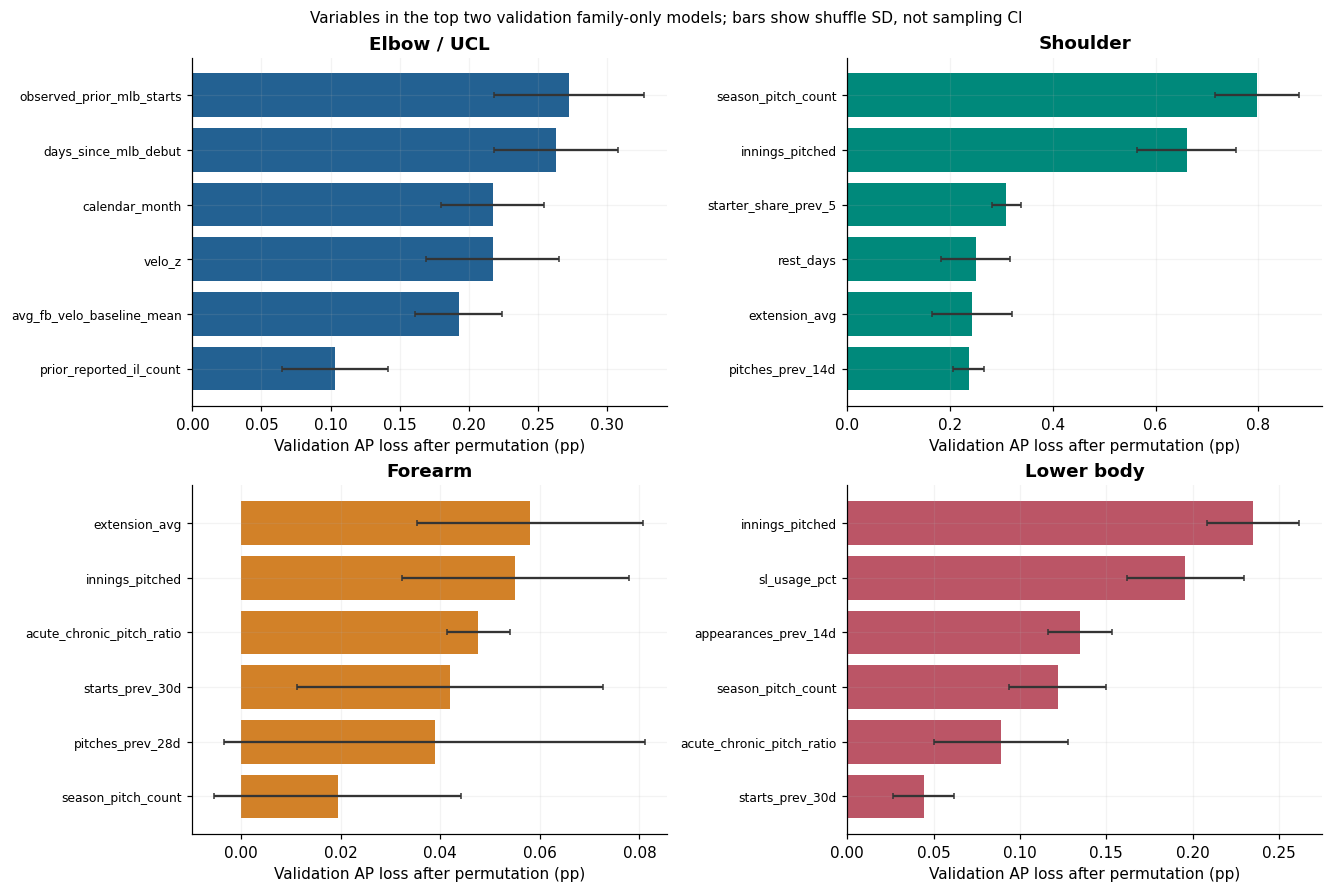

,category,family,feature,mean,std,min,max
67,Shoulder,workload,season_pitch_count,0.007979,0.000817,0.006713,0.008905
60,Shoulder,workload,innings_pitched,0.006602,0.000968,0.005746,0.008212
68,Shoulder,workload,starter_share_prev_5,0.003093,0.000281,0.002700,0.003412
3,Elbow / UCL,pitcher_history,observed_prior_mlb_starts,0.002728,0.000545,0.001965,0.003260
2,Elbow / UCL,pitcher_history,days_since_mlb_debut,0.002632,0.000447,0.002059,0.003240
65,Shoulder,workload,rest_days,0.002502,0.000671,0.001514,0.003326
41,Lower body,workload,innings_pitched,0.002351,0.000266,0.002049,0.002719
1,Elbow / UCL,pitcher_history,calendar_month,0.002175,0.000373,0.001743,0.002741
12,Elbow / UCL,velocity,velo_z,0.002174,0.000482,0.001436,0.002597
36,Lower body,pitch_mix,sl_usage_pct,0.001958,0.000339,0.001489,0.002253


Modern common-row arm-angle comparison: Elbow / UCL; events={'train': 38, 'validation': 89, 'test': 110}


Modern common-row arm-angle comparison: Shoulder; events={'train': 69, 'validation': 115, 'test': 125}


Modern common-row arm-angle comparison: Trunk / neck; events={'train': 57, 'validation': 103, 'test': 65}


Modern common-row arm-angle comparison: Lower body; events={'train': 82, 'validation': 128, 'test': 104}


Modern common-row arm-angle comparison: Hand / wrist; events={'train': 34, 'validation': 32, 'test': 29}


,category,partition,rows,events,run
0,Elbow / UCL,train,12847,38,True
1,Elbow / UCL,validation,26453,89,True
2,Elbow / UCL,test,27472,110,True
3,Shoulder,train,13064,69,True
4,Shoulder,validation,26585,115,True
5,Shoulder,test,27612,125,True
6,Forearm,train,12727,21,False
7,Forearm,validation,26144,41,False
8,Forearm,test,27047,38,False
9,Other arm,train,12744,18,False


,category,partition,average_precision,ap_delta,delta_low,delta_high
2,Elbow / UCL,validation,0.023272,0.000279,-0.000834,0.001513
5,Elbow / UCL,test,0.035218,-0.001522,-0.004152,0.000596
8,Shoulder,validation,0.045216,-0.000043,-0.003577,0.003182
11,Shoulder,test,0.037001,0.000420,-0.000713,0.002270
14,Trunk / neck,validation,0.033716,-0.000832,-0.004880,0.003107
17,Trunk / neck,test,0.031351,-0.000514,-0.007232,0.004724
20,Lower body,validation,0.037151,0.000152,-0.000991,0.001631
23,Lower body,test,0.034649,-0.001725,-0.007816,-0.000147
26,Hand / wrist,validation,0.007172,-0.000338,-0.001590,0.000187
29,Hand / wrist,test,0.007855,0.000200,-0.000438,0.003833


**Computed conclusion.** The full model exceeds WH by point estimate in 3/7 test categories and 3/7 validation categories. Elbow/UCL test AP changes by -0.0018; shoulder by +0.0058; lower body by +0.0003. Forearm's validation/test changes are -0.0004/+0.0094. The paired intervals and period differences do not establish a universal Statcast advantage or a stable ranking of biological injury specificity.

In [5]:
plots.importance_figure();plt.show()
display(read_table('variable_permutation_summary').sort_values('mean',ascending=False).groupby('category').head(4))
modern=run_modern(a,events,spec)
display(read_table('modern_cohort_counts'))
display(modern.query("variant=='Full + arm angle'")[['category','partition','average_precision','ap_delta','delta_low','delta_high']])
f=metrics.query("partition=='test' and variant=='Full'").set_index('category')
v=metrics.query("partition=='validation' and variant=='Full'").set_index('category')
conclusion(f"The full model exceeds WH by point estimate in {f.ap_delta.gt(0).sum()}/7 test categories and {v.ap_delta.gt(0).sum()}/7 validation categories. Elbow/UCL test AP changes by {f.loc['Elbow / UCL','ap_delta']:+.4f}; shoulder by {f.loc['Shoulder','ap_delta']:+.4f}; lower body by {f.loc['Lower body','ap_delta']:+.4f}. Forearm's validation/test changes are {v.loc['Forearm','ap_delta']:+.4f}/{f.loc['Forearm','ap_delta']:+.4f}. The paired intervals and period differences do not establish a universal Statcast advantage or a stable ranking of biological injury specificity.")